# Análisis exploratorio (EDA) – Forum Global Seguros

**Forum Global Seguros** es un bróker de seguros de auto **simulado**, diseñado a partir de mi experiencia
de más de 4 años en la operación de un bróker real (ventas, supervisión y coordinación de campañas).
Los datos se generaron con Python siguiendo reglas de negocio reales (campañas, aseguradoras, formas de pago,
renovaciones y rotación de personal) y se almacenan en **MySQL**. Este notebook complementa el
**dashboard de Power BI** del proyecto.

**Datos:** 703,436 pólizas emitidas (venta nueva y renovaciones), 13 aseguradoras y 18 campañas,
de enero de 2022 a diciembre de 2026.

**Preguntas de negocio:**
1. ¿Cómo ha evolucionado la venta nueva (VN) y en qué momento se estabilizó?
2. De las pólizas emitidas, ¿qué porcentaje realmente se paga? ¿Cambia entre venta nueva y renovación?
3. ¿Qué forma de pago tiene más impago?

**Contenido:**
1. Setup · 2. Carga de datos · 3. Calidad de datos · 4. Preparación · 5. Análisis · 6. Conclusiones y limitaciones

> ⚠️ Los datos son simulados; los nombres de aseguradoras se usan solo como referencia del mercado mexicano.

## 1. Setup
Librerías, formato de números y conexión a la base MySQL. Las credenciales
se leen de la variable de entorno `FORUM_CONN`, para no dejarlas escritas en el código.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
import os

pd.options.display.float_format = '{:,.2f}'.format
engine = create_engine(os.environ['FORUM_CONN'])

## 2. Carga de datos
Se cargan las 4 vistas de MySQL que se usan en el análisis. Las fechas se
convierten a `datetime` desde la carga, con `parse_dates`.

| Tabla | Vista | Contenido |
|---|---|---|
| `polizas` | `vw_fact_polizas` | Una fila por póliza emitida (Venta Nueva y Renovación) |
| `pagos` | `vw_fact_pagos` | Estado del primer recibo de cada póliza |
| `aseguradoras` | `vw_dim_aseguradoras` | Catálogo de aseguradoras |
| `campanias` | `vw_dim_campanas` | Catálogo de campañas y su segmento |

In [2]:
polizas = pd.read_sql('SELECT * FROM vw_fact_polizas', engine,
                      parse_dates=['Fecha_Emision', 'Inicio_Vigencia', 'Fin_Vigencia'])
print(polizas.shape)
polizas.dtypes

(703436, 17)


id_poliza                   int64
numero_poliza              object
id_lead                     int64
id_cliente                  int64
vin                        object
id_empleado                 int64
id_aseguradora              int64
id_campana                  int64
id_cobertura                int64
Fecha_Emision      datetime64[ns]
Inicio_Vigencia    datetime64[ns]
Fin_Vigencia       datetime64[ns]
Tipo_Poliza                object
Tipo_de_pago               object
Estatus_Poliza             object
Prima_Neta                float64
Prima_Total               float64
dtype: object

In [3]:
pagos = pd.read_sql('SELECT * FROM vw_fact_pagos', engine, parse_dates=['Fecha_Pago', 'Fecha_Limite_Pago'])
campanias = pd.read_sql('SELECT * FROM vw_dim_campanas', engine)
aseguradoras = pd.read_sql('SELECT * FROM vw_dim_aseguradoras', engine)

print(pagos.shape, campanias.shape, aseguradoras.shape)

(703436, 10) (18, 6) (13, 2)


## 3. Calidad de datos
Antes de unir y analizar, se revisa que las llaves sean únicas, los nulos
y la consistencia entre tablas.

### 3.1 Llaves únicas

In [4]:
print(f"polizas.id_poliza es único: {polizas['id_poliza'].is_unique}")
print(f"pagos.id_poliza es único: {pagos['id_poliza'].is_unique}")
print(f"aseguradoras.id_aseguradora es único: {aseguradoras['id_aseguradora'].is_unique}")
print(f"campanias.id_campana es único: {campanias['id_campana'].is_unique}")

polizas.id_poliza es único: True
pagos.id_poliza es único: True
aseguradoras.id_aseguradora es único: True
campanias.id_campana es único: True


### 3.2 Nulos

In [5]:
tablas = {
    'polizas': polizas,
    'pagos': pagos,
    'aseguradoras': aseguradoras,
    'campanias': campanias,
}

for nombre, tabla in tablas.items():
    nulos = tabla.isna().sum()
    print(nombre, nulos[nulos > 0].to_dict())

polizas {}
pagos {'Fecha_Pago': 35179}
aseguradoras {}
campanias {}


### 3.3 Columnas sin variación
Una columna con un solo valor en todas las filas no aporta información al
análisis. Se revisa cuántos valores distintos tiene cada columna de `polizas`.

In [6]:
polizas.nunique()

id_poliza          703436
numero_poliza      703436
id_lead            288174
id_cliente         185354
vin                 14440
id_empleado           784
id_aseguradora         13
id_campana             18
id_cobertura            4
Fecha_Emision        1824
Inicio_Vigencia      1824
Fin_Vigencia         1824
Tipo_Poliza             2
Tipo_de_pago            4
Estatus_Poliza          1
Prima_Neta         573585
Prima_Total        573360
dtype: int64

**Hallazgos:** `Estatus_Poliza` únicamente tiene un valor ("Emitida"), por lo que no aporta información al análisis y se excluye. Los conteos de aseguradoras (13), campañas (18), tipos de póliza (2) y formas de pago (4) cuadran con las tablas de dimensión.

**Limitaciones:** solo hay 14,440 VIN distintos para 703,436 pólizas (~49 pólizas por vehículo en promedio). En estos datos simulados el VIN no sirve para analizar vehículos.

### 3.4 Consistencia entre estado de pago y fecha de pago
Una póliza sin pago no debería tener fecha de pago, y una pagada sí. Se comprueba
en los dos sentidos que los nulos de `Fecha_Pago` coincidan con el estado "Vencido / Impago".

In [7]:
pd.crosstab(pagos['Estado_del_pago'], pagos['Fecha_Pago'].isna()).rename(columns={False: 'Con fecha', True: 'Sin fecha'})

Fecha_Pago,Con fecha,Sin fecha
Estado_del_pago,,
Pagado,597952,0
Pagado con Atraso,70305,0
Vencido / Impago,0,35179


**Hallazgo:** la tabla `pagos` es consistente: los 35,179 nulos de `Fecha_Pago` corresponden exactamente a las pólizas en estado "Vencido / Impago" (5% del total), y todas las pagadas (597,952 a tiempo y 70,305 con atraso) tienen fecha de pago.

## 4. Preparación de datos
Se unen las pólizas con su pago, aseguradora y campaña en una sola tabla (`base`),
se excluyen las columnas que no aportan y se crean las columnas de año, mes y pagada.

In [8]:
base = (polizas
        .drop(columns=['vin', 'Estatus_Poliza'])
        .merge(pagos, on='id_poliza', how='left', validate='one_to_one')
        .merge(aseguradoras, on='id_aseguradora', how='left', validate='many_to_one')
        .merge(campanias, on='id_campana', how='left', validate='many_to_one')
        )
print(base.shape)
base.rename(columns={'Campaña': 'campana'}, inplace=True)
base.columns = base.columns.str.lower()
base.head(2)

(703436, 30)


,id_poliza,numero_poliza,id_lead,id_cliente,id_empleado,id_aseguradora,id_campana,id_cobertura,fecha_emision,inicio_vigencia,...,monto_pagado,base_comision,metodo_de_pago,estado_del_pago,aseguradora,id_area,campana,segmento,meta_conversion,cartera_renovacion
0,1,GNP-11316,11316,150518,272,2,7,3,2022-01-03,2022-01-03,...,873.25,752.80,Domiciliación,Pagado,GNP,2,Alianza GNP,Marcas,0.05,Alianza GNP
1,2,BAN-16890,16890,336522,399,3,5,3,2022-01-03,2022-01-03,...,"2,077.66","1,791.08",Tarjeta de Crédito,Pagado,BANORTE,2,Bancaseguros,Marcas,0.06,Bancaseguros


In [9]:
base['anio'] = base['fecha_emision'].dt.year
base['mes'] = base['fecha_emision'].dt.month
base['pagada'] = base['estado_del_pago'].isin(['Pagado', 'Pagado con Atraso'])

In [10]:
# Verificación: las renovaciones sí tienen campaña asignada
base.query("tipo_poliza == 'Renovacion'")['campana'].value_counts(dropna=False)

campana
Renovaciones Multimarcas       202915
Renovaciones Alianza GNP          69636
Renovaciones Alianza Qualitas     67932
Renovaciones Bancaseguros             31176
Renovaciones Plataformas             30908
Renovaciones Motocicletas              12695
Name: count, dtype: int64

In [11]:
for col in base.select_dtypes(include='object').columns:
    if base[col].nunique() < 1000:
        base[col] = base[col].astype('category')
base.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 703436 entries, 0 to 703435
Data columns (total 33 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   id_poliza           703436 non-null  int64         
 1   numero_poliza       703436 non-null  object        
 2   id_lead             703436 non-null  int64         
 3   id_cliente          703436 non-null  int64         
 4   id_empleado         703436 non-null  int64         
 5   id_aseguradora      703436 non-null  int64         
 6   id_campana          703436 non-null  int64         
 7   id_cobertura        703436 non-null  int64         
 8   fecha_emision       703436 non-null  datetime64[ns]
 9   inicio_vigencia     703436 non-null  datetime64[ns]
 10  fin_vigencia        703436 non-null  datetime64[ns]
 11  tipo_poliza         703436 non-null  category      
 12  tipo_de_pago        703436 non-null  category      
 13  prima_neta          703436 no

In [12]:
print(f"Filas: {base.shape[0]:,} | Columnas: {base.shape[1]}")
print(f"% pagadas: {base['pagada'].mean():.1%}")

Filas: 703,436 | Columnas: 33
% pagadas: 95.0%


### Hallazgos de la preparación
- Se unieron las 4 tablas en una sola base de **703,436 filas** y **33 columnas**, sin duplicados (validado con `validate`).
- Se crearon las columnas `anio`, `mes` y `pagada` (`True` si el primer recibo está Pagado o Pagado con Atraso).
- Las columnas de texto con pocos valores se convirtieron a `category` para reducir el uso de memoria y agilizar los `groupby`.
- Se conservó `cartera_renovacion` porque indica a qué cartera pasa cada póliza de venta nueva (VN); se usará para el análisis de renovaciones.
- El 95% de las pólizas tiene su primer pago cubierto (a tiempo o con atraso), lo que coincide con el dashboard de Power BI.

### 4.1 Periodo de análisis

In [13]:
polizas_2026 = base[base['anio'] == 2026]

In [14]:
polizas_2026.groupby('tipo_poliza', observed=True)['fecha_emision'].agg(['count', 'min', 'max'])

,count,min,max
tipo_poliza,,,
Renovacion,183624,2026-01-01,2026-12-31
Venta Nueva,638,2026-01-01,2026-01-05


**Hallazgo:**
- La VN termina el 5 de enero de 2026 (solo 638 pólizas), pero las renovaciones cubren todo 2026 (183,624), porque renuevan la VN de 2025.
- Por eso 2026 no es comparable entre ambos tipos de póliza: el análisis se limita a **2022–2025**, el último periodo en el que los dos tienen años completos.
- En el dashboard de Power BI, la página de Renovaciones sí incluye 2026 (2023–2026), porque ahí solo se analiza la cartera renovada.

In [15]:
# Base de análisis: solo años completos (ver hallazgo 4.1)
base_22_25 = base.query('anio <= 2025')
base_22_25['tipo_poliza'].value_counts()

tipo_poliza
Venta Nueva    287536
Renovacion     231638
Name: count, dtype: int64

## 5. Análisis
### 5.1 Evolución de la venta nueva (VN)

In [16]:
vn_22_25 = base_22_25.query('tipo_poliza == "Venta Nueva"')
vn_22_25.shape

(287536, 33)

In [17]:
venta_anual = vn_22_25.groupby('anio').agg(
    total_polizas=('id_poliza', 'count')
)
venta_anual['pct_crecimiento'] = (venta_anual['total_polizas'].pct_change() * 100).round(1)
venta_anual

,total_polizas,pct_crecimiento
anio,,
2022,32359,NaN
2023,64055,98.00
2024,95387,48.90
2025,95735,0.40


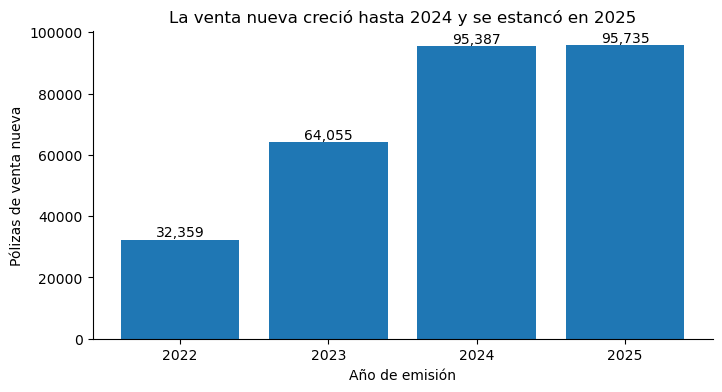

In [18]:
pag, graf = plt.subplots(figsize=(8, 4))
barras = graf.bar(venta_anual.index, venta_anual['total_polizas'])
graf.set_xticks(venta_anual.index)

graf.set_title('La venta nueva creció hasta 2024 y se estancó en 2025')
graf.set_xlabel('Año de emisión')
graf.set_ylabel('Pólizas de venta nueva')
graf.bar_label(barras, fmt='{:,.0f}')
graf.spines[['top', 'right']].set_visible(False)
plt.show()

**Hallazgo:**
- La VN pasó de 32,359 pólizas en 2022 a 95,735 en 2025 (casi se triplicó).
- El mayor crecimiento fue en 2023 (+98%).
- En 2025 la VN se estancó (+0.4%).
- 2026 se excluye (ver 4.1).

In [19]:
vn_mensual = vn_22_25.pivot_table(
    index='mes',
    columns='anio',
    values='id_poliza',
    aggfunc='count'
)
vn_mensual

anio,2022,2023,2024,2025
mes,,,,
1,791,4090,7892,7958
2,1033,4031,7755,7747
3,1567,4458,7954,8032
4,1740,4391,7827,7856
5,2198,4673,8020,8295
6,2600,4960,8124,8236
7,3115,4997,7839,7905
8,3627,5294,7976,7881
9,3693,5559,7789,7817


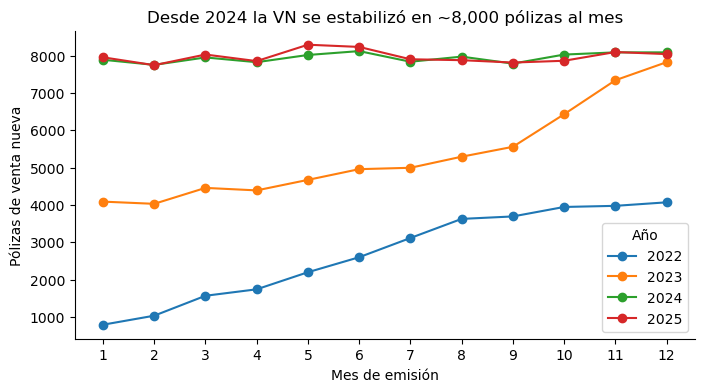

In [20]:
pag, graf = plt.subplots(figsize=(8, 4))

for anio in vn_mensual.columns:
    graf.plot(vn_mensual.index, vn_mensual[anio], marker='o', label=anio)

graf.set_xticks(range(1, 13))
graf.set_title('Desde 2024 la VN se estabilizó en ~8,000 pólizas al mes')
graf.set_xlabel('Mes de emisión')
graf.set_ylabel('Pólizas de venta nueva')
graf.legend(title='Año')
graf.spines[['top', 'right']].set_visible(False)
plt.show()

**Hallazgo:**
- La columna Total sugiere que diciembre es el mejor mes, pero es un efecto del crecimiento de 2022 y 2023.
- En 2024 y 2025 la VN se mantiene entre 7,750 y 8,300 pólizas al mes; el mejor mes supera al promedio como máximo en 4%.
- No hay estacionalidad marcada: la VN alcanzó un techo de ~8,000 pólizas mensuales.
- Pendiente: entender el salto del último trimestre de 2023.

### 5.2 Emitidas vs pagadas

In [21]:
pago_por_tipo = base_22_25.groupby('tipo_poliza', observed=True).agg(
    emitidas=('id_poliza', 'count'),
    pagadas=('pagada', 'sum'),
    pct_pagadas=('pagada', 'mean')
)
pago_por_tipo['pct_pagadas'] = (pago_por_tipo['pct_pagadas'] * 100).round(1)
pago_por_tipo

,emitidas,pagadas,pct_pagadas
tipo_poliza,,,
Renovacion,231638,220139,95.00
Venta Nueva,287536,273186,95.00


In [22]:
(pd.crosstab(base_22_25['tipo_poliza'], base_22_25['estado_del_pago'], normalize='index') * 100).round(1)

estado_del_pago,Pagado,Pagado con Atraso,Vencido / Impago
tipo_poliza,,,
Renovacion,85.00,10.10,5.00
Venta Nueva,85.00,10.00,5.00


**Hallazgo:**
- VN y renovación tienen la misma tasa de pago: 95% de las pólizas emitidas tiene su primer recibo cubierto.
- El desglose también es igual en ambos: ~85% pagado a tiempo, ~10% con atraso y ~5% vencido / impago.
- El tipo de póliza no explica quién paga y quién no. En la 5.3 se revisa si la forma de pago sí lo explica.

**Limitación:** la simulación asignó la misma distribución de pago (85/10/5) a todas las pólizas.
En datos reales se esperaría más impago en venta nueva, por errores de emisión que requieren endoso,
cancelaciones antes del primer pago, falta de seguimiento o ventas duplicadas cerradas por otra campaña;
el cliente que renueva ya tiene historial de pago y, con frecuencia, cobro domiciliado.

### 5.3 Forma de pago e impago

In [23]:
(base_22_25['tipo_de_pago'].value_counts(normalize=True) * 100).round(1)

tipo_de_pago
Anual        60.20
Mensual      19.90
Semestral    11.40
Trimestral    8.50
Name: proportion, dtype: float64

In [24]:
(pd.crosstab(base_22_25['tipo_de_pago'], base_22_25['estado_del_pago'], normalize='index') * 100).round(1)

estado_del_pago,Pagado,Pagado con Atraso,Vencido / Impago
tipo_de_pago,,,
Anual,85.00,10.00,5.00
Mensual,84.90,10.10,5.00
Semestral,85.50,9.80,4.70
Trimestral,85.00,10.00,5.00


In [25]:
(pd.crosstab(base_22_25['anio'], base_22_25['tipo_de_pago'], normalize='index') * 100).round(1)

tipo_de_pago,Anual,Mensual,Semestral,Trimestral
anio,,,,
2022,39.40,30.20,15.00,15.30
2023,49.30,24.90,14.20,11.60
2024,60.10,20.00,11.80,8.10
2025,67.50,16.30,9.60,6.60


In [26]:
mezcla_vn = (pd.crosstab(vn_22_25['anio'], vn_22_25['tipo_de_pago'], normalize='index') * 100).round(1)
mezcla_vn

tipo_de_pago,Anual,Mensual,Semestral,Trimestral
anio,,,,
2022,39.40,30.20,15.00,15.30
2023,53.20,22.80,13.90,10.20
2024,68.20,16.30,10.00,5.50
2025,77.90,11.30,6.40,4.40


In [27]:
reno_2025 = base_22_25.query("tipo_poliza == 'Renovacion' and anio == 2025")['tipo_de_pago']

conteo = reno_2025.value_counts()
pct = (reno_2025.value_counts(normalize=True) * 100).round(1)
pd.concat([conteo, pct], axis=1).rename(columns={'count': 'conteo', 'proportion': 'pct'})

,conteo,pct
tipo_de_pago,,
Anual,80358,60.10
Mensual,26660,19.90
Semestral,15864,11.90
Trimestral,10913,8.20


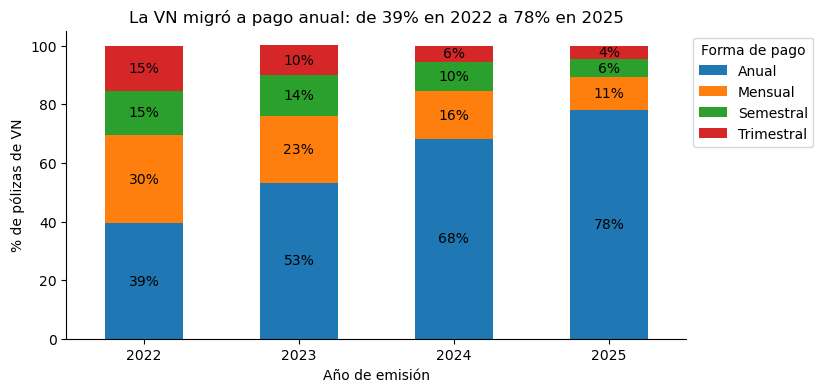

In [28]:
pag, graf = plt.subplots(figsize=(8, 4))
mezcla_vn.plot(kind='bar', stacked=True, ax=graf, rot=0)

graf.set_title('La VN migró a pago anual: de 39% en 2022 a 78% en 2025')
graf.set_xlabel('Año de emisión')
graf.set_ylabel('% de pólizas de VN')
graf.legend(title='Forma de pago', bbox_to_anchor=(1, 1), loc='upper left')
graf.spines[['top', 'right']].set_visible(False)
for barras in graf.containers:
    graf.bar_label(barras, fmt='{:.0f}%', label_type='center')

plt.show()

**Hipótesis (experiencia en operación):** se esperaba más impago en pago Anual (monto alto en un solo cargo, rechazos del banco,
tarjetas que no aplican a MSI) y menos en Mensual (cobro domiciliado).

**Hallazgo:**
- Los datos no confirman la hipótesis: todas las formas de pago tienen ~5% de impago. La forma de pago no explica quién paga y quién no.
- La mezcla de la VN migró hacia pago anual: de 39% en 2022 a 78% en 2025, mientras que Mensual bajó de 30.2% a 11.3%.
- En el total de pólizas, Anual solo llega a 67.5% en 2025, porque las renovaciones copian la forma de pago de la póliza original y arrastran la mezcla de años anteriores.

**Oportunidad:** 26,660 renovaciones de 2025 (19.9%) siguen en pago mensual. Migrarlas a anual en su siguiente renovación
aumentaría la prima cobrada por adelantado, como se hacía en la operación real.

**Limitación:** la simulación asignó la misma probabilidad de pago a todas las formas de pago y no modela el cambio de Mensual a Anual al renovar.

## 6. Conclusiones y limitaciones

### Conclusiones
1. **Venta nueva:** la VN casi se triplicó entre 2022 y 2025 (de 32,359 a 95,735 pólizas). El mayor salto fue en 2023 (+98%) y desde 2024 se estabilizó en un techo de ~8,000 pólizas al mes, sin estacionalidad marcada (+0.4% en 2025).
2. **Emitidas vs pagadas:** el 95% de las pólizas emitidas tiene su primer recibo cubierto, tanto en venta nueva como en renovación (85% a tiempo, 10% con atraso y 5% vencido / impago). El tipo de póliza no explica el impago.
3. **Forma de pago:** todas las formas de pago tienen ~5% de impago, por lo que tampoco explican quién paga. Lo que sí cambió fue la mezcla: en la VN, el pago Anual pasó de 39% en 2022 a 78% en 2025, y Mensual bajó de 30.2% a 11.3%. En el total de pólizas, Anual solo llega a 67.5%, porque las renovaciones conservan la forma de pago original.

### Recomendaciones
- **Migrar a pago anual las renovaciones mensuales:** en 2025 hubo 26,660 renovaciones en pago mensual (19.9%). Ofrecer el cambio a anual en su siguiente renovación aumentaría la prima cobrada por adelantado.
- **Investigar la causa raíz del techo de ~8,000 pólizas al mes** antes de invertir en más leads o contrataciones. Factores internos: HC de ejecutivos, leads asignados, conversión por campaña, rotación y tiempo de capacitación de los nuevos ingresos. Factores comerciales: promociones activas, descuentos de las aseguradoras al bróker y siniestralidad por aseguradora. Primera pista: en el dashboard de RH, el HC de ejecutivos se estabilizó en ~290–304 en 2024–2025, el mismo periodo en que la VN dejó de crecer, y uno de cada cinco ejecutivos está en sus primeros 3 meses por la rotación.

### Limitaciones
- Los datos son simulados: la distribución de pago (85/10/5) es igual en todas las pólizas, por lo que no se pueden detectar diferencias reales de impago por tipo de póliza, forma de pago o campaña.
- La renovación copia la forma de pago de la póliza original; no modela el cambio de Mensual a Anual que se buscaba en la operación real.
- Solo existen 14,440 VIN distintos para 703,436 pólizas (~49 pólizas por vehículo), por lo que el análisis por vehículo no es posible.
- El análisis se limita a 2022–2025, porque la VN termina el 5 de enero de 2026 (ver 4.1).

### Siguientes pasos
- Explicar el salto de la VN en el último trimestre de 2023, cruzando las ventas con la fecha de lanzamiento de cada campaña y el HC de ejecutivos.
- En una versión 2 de la simulación: modelar más impago en venta nueva y en pago anual, y la migración de Mensual a Anual al renovar, para validar las hipótesis de la operación real.